<a href="https://colab.research.google.com/github/fariasad/UCSC-Ciencia-de-Datos/blob/main/S3_Entrega2_ARIAS_FREDDY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 3 — Análisis exploratorio de tu conjunto de datos
**Ciencia de Datos · Semana 3 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA2 (parte 1) · RA3 (transversal) |
| **Duración estimada** | 1,5 h asincrónicas + 1 h de trabajo autónomo |
| **Insumo** | `S2_Online_Retail_Limpio.csv`, producido en la semana 2 |
| **Producto** | Este cuaderno completo — **es la Entrega 2** |
| **Estudiante** | Freddy Antonio Arias Adasme |

---

⚠️ **Esta semana no hay sesión sincrónica.** El tiempo se destina a este laboratorio, que es el más extenso del curso. Las dudas van al **Foro de Consultas**, con respuesta dentro de 24 horas hábiles.

**Este cuaderno es la entrega.** No hay informe aparte. Lo que se evalúa es que cada resultado venga acompañado de su lectura: *un resultado sin interpretación no es un hallazgo, es un número suelto*.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20263
np.random.seed(SEMILLA)
plt.rcParams['figure.figsize'] = (9, 4)

# Cargar el conjunto preparado en la Semana 2
ARCHIVO = 'S2_Online_Retail_Limpio.csv'

df = pd.read_csv(
    RUTA + ARCHIVO,
    sep=';',
    encoding='utf-8-sig',
    dtype={
        'InvoiceNo': 'string',
        'StockCode': 'string',
        'CustomerID': 'string'
    },
    parse_dates=['InvoiceDate']
)

print("Formato:", df.shape)
print("Fecha inicial:", df['InvoiceDate'].min())
print("Fecha final:", df['InvoiceDate'].max())

display(df.head())

Formato: (541909, 18)
Fecha inicial: 2010-12-01 08:26:00
Fecha final: 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Country_norm,ImporteLinea,Anio,Mes,AnioMes,TipoOperacion,Tipo_AJUSTE,Tipo_CANCELACION,Tipo_CANTIDAD_NEGATIVA,Tipo_VENTA
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,UNITED KINGDOM,15.30,2010,12,2010-12,VENTA,0,0,0,1
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,UNITED KINGDOM,22.00,2010,12,2010-12,VENTA,0,0,0,1
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,UNITED KINGDOM,20.34,2010,12,2010-12,VENTA,0,0,0,1


### Punto de partida

Antes de explorar, recuerda a dónde vas. Copia aquí lo que escribiste en la Entrega 1:

- **Mi pregunta analítica es:** _¿Cuáles son los productos que generan mayores ingresos en las transacciones de Online Retail y cómo varían sus ventas a lo largo del tiempo?_
- **Una fila de mi conjunto representa:** _Una línea de factura que registra un producto, su cantidad, precio unitario y fecha de transacción. Una factura puede contener varias líneas de productos._

Todo lo que sigue debe servir para responder esa pregunta. Si un gráfico no aporta a ella, sobra.

---
## Parte 1 · Análisis univariado

Una variable a la vez. El objetivo es conocer la forma de cada una antes de relacionarlas.

In [5]:
# Resumen numérico de todas las variables cuantitativas
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
Quantity,541909.0,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
ImporteLinea,541909.0,17.987795,-168469.6,3.4,9.75,17.4,168469.6,378.810824
Anio,541909.0,2010.921609,2010.0,2011.0,2011.0,2011.0,2011.0,0.268787
Mes,541909.0,7.553128,1.0,5.0,8.0,11.0,12.0,3.509055
Tipo_AJUSTE,541909.0,0.000063,0.0,0.0,0.0,0.0,1.0,0.007921
Tipo_CANCELACION,541909.0,0.017139,0.0,0.0,0.0,0.0,1.0,0.129791
Tipo_CANTIDAD_NEGATIVA,541909.0,0.002447,0.0,0.0,0.0,0.0,1.0,0.049406
Tipo_VENTA,541909.0,0.980351,0.0,1.0,1.0,1.0,1.0,0.138791


**Interpretación del resumen estadístico**

Al revisar los resultados, observo que las medias de Quantity, UnitPrice e ImporteLinea son mayores que sus respectivas medianas. Esto indica que existen valores altos que influyen en los promedios.

En Quantity, por ejemplo, la media es 9,55 y la mediana es 3, lo que muestra que la mayoría de las líneas de factura tienen cantidades menores que el promedio.

También aparecen valores negativos y extremos, que pueden corresponder a cancelaciones o ajustes. Como ya identificamos estas situaciones en la Semana 2, debemos considerarlas al interpretar los resultados.

Para describir una operación típica, considero más adecuado utilizar la mediana, porque es menos sensible a estos valores extremos.

### ✏️ Actividad 1.1 — Distribuciones

Grafica el histograma de **al menos tres variables numéricas** relevantes para tu pregunta. Para cada una, responde en la celda de texto siguiente:

- ¿Es simétrica o asimétrica? ¿Hacia qué lado?
- ¿Tiene una joroba o más de una? Si tiene más de una, **busca la categoría que la explica** (Ejercicio 1 del cuaderno resuelto).
- ¿Ves picos regulares o valores que se repiten sospechosamente? (Ejercicio 3).


=== Quantity ===
Registros totales: 541909
Registros dentro del rango visual: 531914
Registros fuera del rango visual: 9995
Media: 9.55
Mediana: 3.0
Asimetría: -0.26


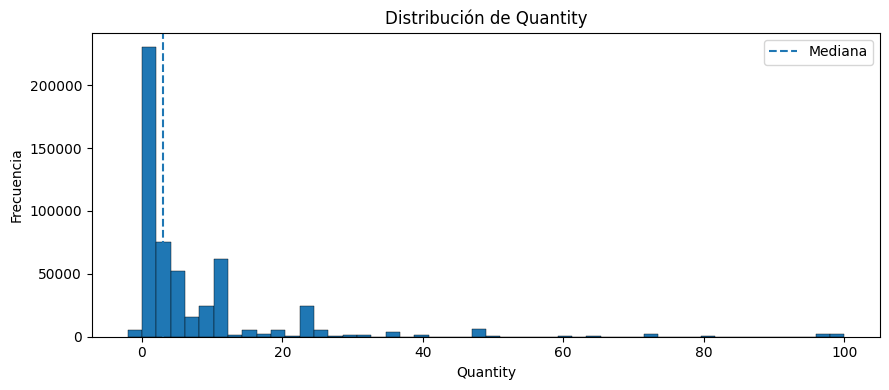


Valores más frecuentes:


,count
Quantity,
1,148227
2,81829
12,61063
6,40868
4,38484
3,37121
24,24021
10,22288
8,13129



=== UnitPrice ===
Registros totales: 541909
Registros dentro del rango visual: 533480
Registros fuera del rango visual: 8429
Media: 4.61
Mediana: 2.08
Asimetría: 186.51


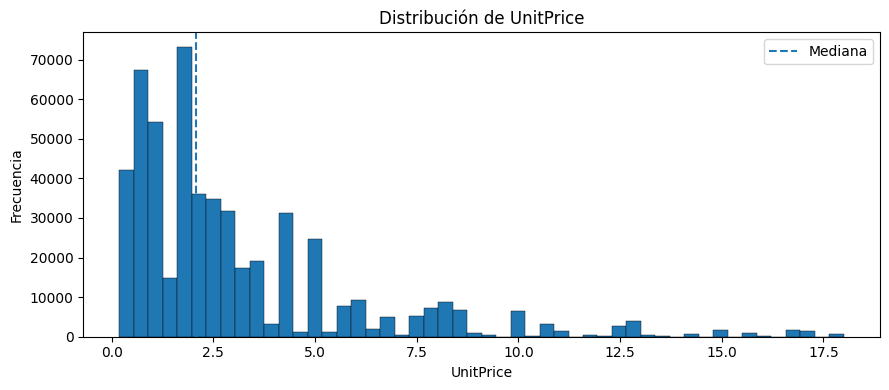


Valores más frecuentes:


,count
UnitPrice,
1.25,50496
1.65,38181
0.85,28497
2.95,27768
0.42,24533
4.95,19040
3.75,18600
2.10,17697
2.46,17091



=== ImporteLinea ===
Registros totales: 541909
Registros dentro del rango visual: 531121
Registros fuera del rango visual: 10788
Media: 17.99
Mediana: 9.75
Asimetría: -0.96


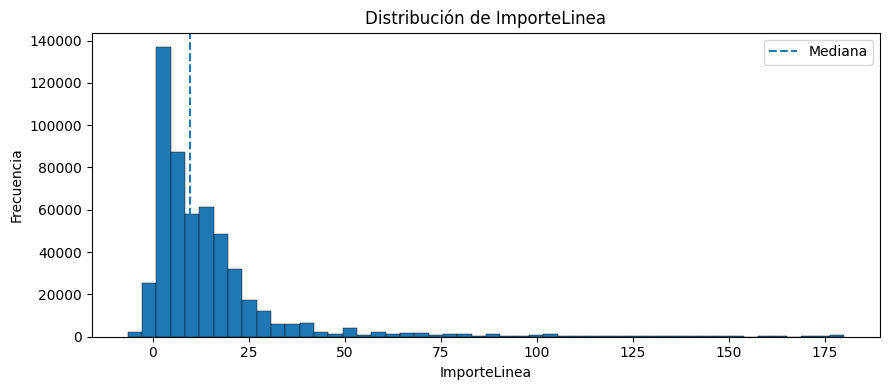


Valores más frecuentes:


,count
ImporteLinea,
15.00,20267
19.80,11114
1.25,9550
2.46,9275
17.70,9250
4.13,8811
16.50,8533
10.20,8099
3.75,7455


In [6]:
# Actividad 1.1 — Distribuciones de Online Retail

variables = ['Quantity', 'UnitPrice', 'ImporteLinea']

for columna in variables:
    datos = df[columna].dropna()

    # Límites visuales entre percentiles 1 y 99
    limite_inf = datos.quantile(0.01)
    limite_sup = datos.quantile(0.99)

    datos_visibles = datos.between(limite_inf, limite_sup)

    print(f"\n=== {columna} ===")
    print("Registros totales:", len(datos))
    print("Registros dentro del rango visual:",
          datos_visibles.sum())
    print("Registros fuera del rango visual:",
          (~datos_visibles).sum())
    print("Media:", round(datos.mean(), 2))
    print("Mediana:", round(datos.median(), 2))
    print("Asimetría:", round(datos.skew(), 2))

    plt.figure(figsize=(9, 4))

    plt.hist(
        datos[datos_visibles],
        bins=50,
        edgecolor='black',
        linewidth=0.3
    )

    plt.axvline(
        datos.median(),
        linestyle='--',
        label='Mediana'
    )

    plt.title(f'Distribución de {columna}')
    plt.xlabel(columna)
    plt.ylabel('Frecuencia')
    plt.legend()
    plt.tight_layout()
    plt.show()

    # Examinar valores más frecuentes
    print("\nValores más frecuentes:")
    display(datos.value_counts().head(10))


**Mi lectura de las tres distribuciones:**

Quantity: La mayoría de las transacciones registra cantidades pequeñas y el gráfico muestra una cola hacia la derecha. Se observan varios picos, especialmente en cantidades de 1, 2, 6 y 12 unidades. Esto podría relacionarse con compras individuales o por lotes. La media es 9,55 y la mediana es 3. Aunque el gráfico muestra una cola positiva, la asimetría calculada es -0,26 debido a los valores negativos extremos del conjunto completo.

UnitPrice: Los precios se concentran principalmente en valores bajos, con varios picos y una cola hacia la derecha. La asimetría es bastante alta (186,51), debido a precios extremos. También hay precios que se repiten frecuentemente, como 1,25 y 1,65, lo que podría corresponder a productos con precios habituales dentro del catálogo.

ImporteLinea: La mayoría de los importes se encuentra en valores bajos, aunque existen operaciones de montos elevados. Se observan varios picos, destacando los importes de 15,00 y 19,80. El gráfico presenta una cola hacia la derecha, pero la asimetría global es -0,96 porque existen importes negativos extremos asociados a movimientos especiales.

Conclusión: Las tres distribuciones presentan concentraciones y valores extremos que afectan sus promedios. Por eso considero que la mediana representa mejor los valores habituales de las transacciones. Además, las repeticiones observadas pueden corresponder a patrones normales de compra y no necesariamente a errores.

### ✏️ Actividad 1.2 — Media contra mediana

Para tu variable numérica principal, compara media, mediana y sesgo. Decide cuál de las dos reportarías en un informe y justifícalo.

=== ANÁLISIS DE IMPORTELINEA ===
Registros: 541909
Media: 17.99
Mediana: 9.75
Asimetría: -0.96
Diferencia media - mediana: 8.24


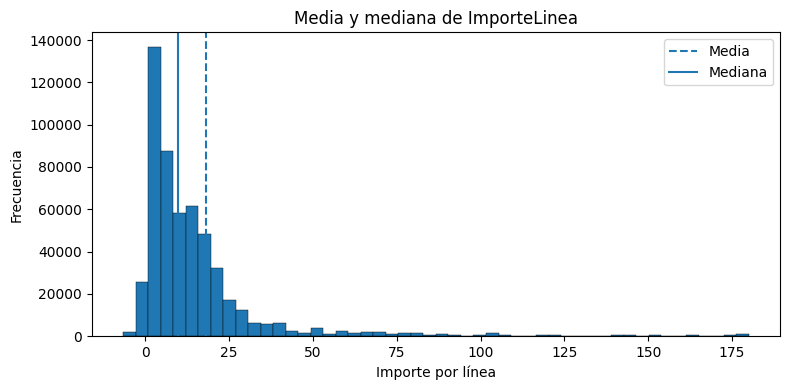

In [7]:
# Actividad 1.2 — Media contra mediana

variable = 'ImporteLinea'

datos = df[variable].dropna()

media = datos.mean()
mediana = datos.median()
sesgo = datos.skew()

print("=== ANÁLISIS DE IMPORTELINEA ===")
print("Registros:", len(datos))
print("Media:", round(media, 2))
print("Mediana:", round(mediana, 2))
print("Asimetría:", round(sesgo, 2))
print("Diferencia media - mediana:", round(media - mediana, 2))

# Comparar visualmente ambas medidas
plt.figure(figsize=(8, 4))

plt.hist(
    datos[datos.between(
        datos.quantile(0.01),
        datos.quantile(0.99)
    )],
    bins=50,
    edgecolor='black',
    linewidth=0.3
)

plt.axvline(media, linestyle='--', label='Media')
plt.axvline(mediana, linestyle='-', label='Mediana')

plt.title('Media y mediana de ImporteLinea')
plt.xlabel('Importe por línea')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

**Justificación:**


Elegí ImporteLinea porque permite analizar el importe asociado a cada producto.

La media es 17,99 y la mediana es 9,75. Esta diferencia muestra que los valores extremos influyen en el promedio. Además, la asimetría es -0,96, debido en parte a los importes negativos extremos que existen en el conjunto.

Para un informe utilizaría la mediana, porque representa mejor el importe habitual de una línea de factura y se ve menos afectada por valores extremos. Sin embargo, para calcular los ingresos totales por producto utilizaría la suma de ImporteLinea, diferenciando las ventas de las cancelaciones y ajustes.



### ✏️ Actividad 1.3 — Variables categóricas

Muestra la frecuencia de tus variables categóricas. Fíjate en dos cosas: categorías con muy pocos casos (¿conviene agruparlas?) y categorías que dominan el conjunto (¿sesgan la conclusión?).

In [8]:
# Actividad 1.3 — Variables categóricas

columnas = ['Country_norm', 'TipoOperacion', 'StockCode']

for columna in columnas:
    frecuencias = df[columna].value_counts(dropna=False)
    porcentajes = df[columna].value_counts(
        normalize=True, dropna=False
    ) * 100

    resumen = pd.DataFrame({
        'Frecuencia': frecuencias,
        'Porcentaje': porcentajes.round(2)
    })

    print(f"\n=== {columna} ===")
    print("Categorías distintas:",
          df[columna].nunique(dropna=True))

    print("\n10 categorías más frecuentes:")
    display(resumen.head(10))

    print("Categorías con menos de 10 registros:",
          (frecuencias < 10).sum())

    print("Registros en categorías con menos de 10 casos:",
          frecuencias[frecuencias < 10].sum())

    print("Porcentaje de la categoría principal:",
          round(porcentajes.iloc[0], 2), "%")


=== Country_norm ===
Categorías distintas: 38

10 categorías más frecuentes:


,Frecuencia,Porcentaje
Country_norm,,
UNITED KINGDOM,495478,91.43
GERMANY,9495,1.75
FRANCE,8557,1.58
IRELAND,8196,1.51
SPAIN,2533,0.47
NETHERLANDS,2371,0.44
BELGIUM,2069,0.38
SWITZERLAND,2002,0.37
PORTUGAL,1519,0.28


Categorías con menos de 10 registros: 0
Registros en categorías con menos de 10 casos: 0
Porcentaje de la categoría principal: 91.43 %

=== TipoOperacion ===
Categorías distintas: 4

10 categorías más frecuentes:


,Frecuencia,Porcentaje
TipoOperacion,,
VENTA,531261,98.04
CANCELACION,9288,1.71
CANTIDAD_NEGATIVA,1326,0.24
AJUSTE,34,0.01


Categorías con menos de 10 registros: 0
Registros en categorías con menos de 10 casos: 0
Porcentaje de la categoría principal: 98.04 %

=== StockCode ===
Categorías distintas: 4070

10 categorías más frecuentes:


,Frecuencia,Porcentaje
StockCode,,
85123A,2313,0.43
22423,2203,0.41
85099B,2159,0.4
47566,1727,0.32
20725,1639,0.3
84879,1502,0.28
22720,1477,0.27
22197,1476,0.27
21212,1385,0.26


Categorías con menos de 10 registros: 827
Registros en categorías con menos de 10 casos: 3058
Porcentaje de la categoría principal: 0.43 %


**Interpretación de las variables categóricas**

Países: El conjunto contiene 38 categorías de países, pero Reino Unido concentra el 91,43 % de los registros. Esto significa que los resultados generales estarán muy influenciados por ese país. Para comparar países, será importante considerar cuántos registros tiene cada uno.

Tipos de operación: El 98,04 % de los registros está clasificado como VENTA, mientras que las cancelaciones representan el 1,71 %. Las cantidades negativas y los ajustes tienen una participación mucho menor. Aunque predominan las ventas, debemos diferenciar los tipos de operación al calcular los ingresos.

Productos: Se identificaron 4.070 códigos de productos distintos. El más frecuente aparece en solo el 0,43 % de los registros, por lo que no existe un producto que domine claramente por cantidad de líneas. Además, 827 productos tienen menos de 10 registros, lo que dificulta obtener conclusiones confiables sobre ellos.

Conclusión: No considero necesario agrupar los países ni los productos con pocos registros por ahora, porque podríamos perder información útil. Sin embargo, para realizar comparaciones tendremos que considerar el tamaño de cada grupo y evitar sacar conclusiones a partir de muy pocos casos.

---
## Parte 2 · Análisis bivariado y agrupación

Ahora las relaciones. Aquí es donde empiezan a aparecer los hallazgos, y también los espejismos.

### ✏️ Actividad 2.1 — Comportamiento por grupo

Agrupa por tu variable categórica más importante y compara una métrica numérica entre grupos. Usa `groupby` con al menos tres estadísticos (`count`, `median`, `std`).

**Incluye siempre el `count`.** Una diferencia espectacular entre grupos deja de serlo cuando uno de ellos tiene cuatro casos.

=== COMPARACIÓN DE IMPORTES POR PAÍS ===
Países analizados: 38


,count,mean,median,std,total,porcentaje_registros
Country_norm,,,,,,
UNITED KINGDOM,495478,16.53,8.29,394.84,8187806.36,91.43
GERMANY,9495,23.35,16.60,37.32,221698.21,1.75
FRANCE,8557,23.07,16.50,117.18,197403.90,1.58
IRELAND,8196,32.12,17.34,94.98,263276.82,1.51
SPAIN,2533,21.62,15.00,83.93,54774.58,0.47
NETHERLANDS,2371,120.06,91.80,164.28,284661.54,0.44
BELGIUM,2069,19.77,16.60,15.58,40910.96,0.38
SWITZERLAND,2002,28.16,17.40,35.86,56385.35,0.37
PORTUGAL,1519,19.33,15.80,74.48,29367.02,0.28



Países con menos de 100 registros:


,count,mean,median,std,total,porcentaje_registros
Country_norm,,,,,,
UNITED ARAB EMIRATES,68,27.97,20.40,24.41,1902.28,0.01
EUROPEAN COMMUNITY,61,21.18,17.70,11.51,1291.75,0.01
RSA,58,17.28,16.50,6.49,1002.31,0.01
LEBANON,45,37.64,31.60,29.12,1693.88,0.01
LITHUANIA,35,47.46,45.00,23.82,1661.06,0.01
BRAZIL,32,35.74,19.65,32.90,1143.60,0.01
CZECH REPUBLIC,30,23.59,25.30,26.30,707.72,0.01
BAHRAIN,19,28.86,25.50,73.82,548.40,0.00
SAUDI ARABIA,10,13.12,17.70,10.86,131.17,0.00


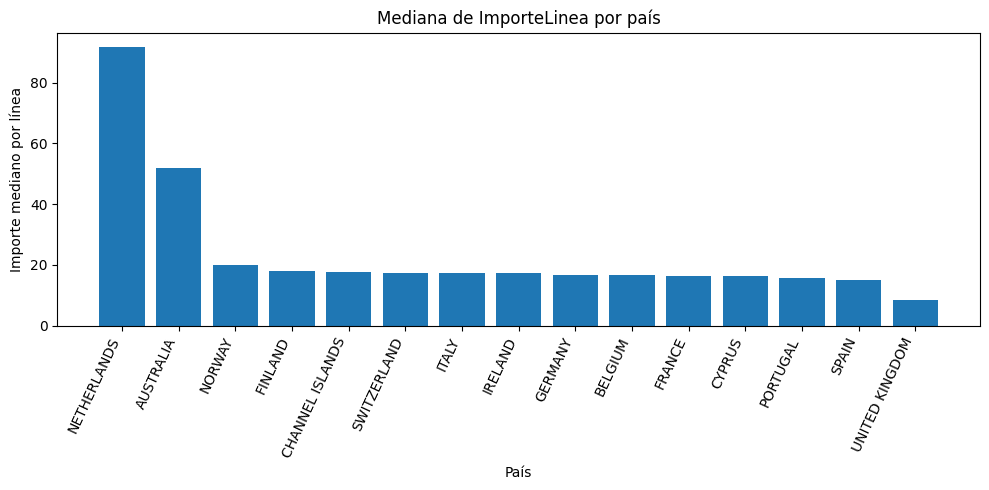

In [9]:
# Actividad 2.1 — Comparación de importes por país

resumen_pais = (
    df.groupby('Country_norm', dropna=False)['ImporteLinea']
    .agg(
        count='count',
        mean='mean',
        median='median',
        std='std',
        total='sum'
    )
    .sort_values('count', ascending=False)
)

# Calcular participación de cada país
resumen_pais['porcentaje_registros'] = (
    resumen_pais['count'] / len(df) * 100
)

# Redondear resultados
resumen_pais = resumen_pais.round(2)

print("=== COMPARACIÓN DE IMPORTES POR PAÍS ===")
print("Países analizados:", len(resumen_pais))

display(resumen_pais.head(15))

# Identificar grupos pequeños
print("\nPaíses con menos de 100 registros:")
display(resumen_pais[resumen_pais['count'] < 100])

# Comparación gráfica de las medianas
# Solo países con al menos 500 registros
paises_comparables = resumen_pais[
    resumen_pais['count'] >= 500
].sort_values('median', ascending=False)

plt.figure(figsize=(10, 5))

plt.bar(
    paises_comparables.index,
    paises_comparables['median']
)

plt.title('Mediana de ImporteLinea por país')
plt.xlabel('País')
plt.ylabel('Importe mediano por línea')
plt.xticks(rotation=65, ha='right')
plt.tight_layout()
plt.show()


**Interpretación del comportamiento por país**

Al comparar los países, observo que Reino Unido concentra el 91,43 % de los registros, pero tiene una mediana de ImporteLinea de 8,29. En cambio, Países Bajos presenta una mediana de 91,80 y Australia de 51,84, aunque tienen muchos menos registros.

Esto muestra que tener más transacciones registradas no significa necesariamente tener importes más altos por línea de factura. Las diferencias podrían relacionarse con las cantidades compradas o los tipos de productos.

También hay países con muy pocos registros, como Líbano (45) y Lituania (35), por lo que sus resultados deben interpretarse con precaución. Además, los importes incluyen cancelaciones y ajustes, que pueden afectar las comparaciones.

Por ahora, estos resultados muestran diferencias entre países, pero no permiten explicar sus causas.



### ✏️ Actividad 2.2 — Matriz de correlación

Calcula y grafica la matriz de correlación de tus variables numéricas. Identifica los dos pares con mayor correlación.

=== MATRIZ DE CORRELACIÓN ===


,Quantity,UnitPrice,ImporteLinea
Quantity,1.0000,-0.0012,0.8867
UnitPrice,-0.0012,1.0000,-0.1620
ImporteLinea,0.8867,-0.1620,1.0000


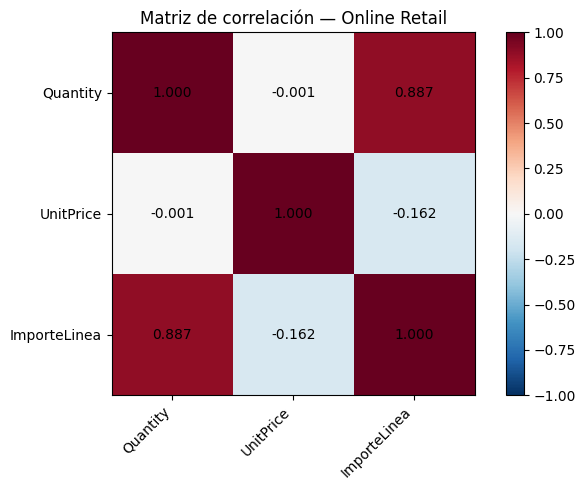


=== DOS PARES CON MAYOR CORRELACIÓN ===


,Variable 1,Variable 2,Correlación
1,Quantity,ImporteLinea,0.8867
2,UnitPrice,ImporteLinea,-0.1620


In [10]:
# Actividad 2.2 — Matriz de correlación

# Variables numéricas relevantes para nuestro análisis
variables = ['Quantity', 'UnitPrice', 'ImporteLinea']

# Correlación de Pearson
corr = df[variables].corr()

print("=== MATRIZ DE CORRELACIÓN ===")
display(corr.round(4))

# Graficar la matriz
fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')

ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(len(corr.columns)):
        ax.text(
            j, i,
            f'{corr.iloc[i, j]:.3f}',
            ha='center',
            va='center'
        )

plt.colorbar(im, ax=ax)
plt.title('Matriz de correlación — Online Retail')
plt.tight_layout()
plt.show()

# Identificar los pares más correlacionados
pares = []

for i in range(len(variables)):
    for j in range(i + 1, len(variables)):
        valor = corr.iloc[i, j]

        pares.append({
            'Variable 1': variables[i],
            'Variable 2': variables[j],
            'Correlación': valor,
            'Valor absoluto': abs(valor)
        })

pares_df = pd.DataFrame(pares)

pares_df = pares_df.sort_values(
    'Valor absoluto',
    ascending=False
)

print("\n=== DOS PARES CON MAYOR CORRELACIÓN ===")

display(
    pares_df.head(2)[
        ['Variable 1', 'Variable 2', 'Correlación']
    ].round(4)
)

**Interpretación de la matriz de correlación**

La correlación más alta se presenta entre Quantity e ImporteLinea (0,8867), lo que indica una asociación positiva fuerte. Esto tiene sentido porque el importe se calcula multiplicando la cantidad por el precio unitario.

El segundo par con mayor correlación absoluta es UnitPrice e ImporteLinea (-0,1620), aunque su relación es negativa y débil. Por otra parte, Quantity y UnitPrice prácticamente no presentan correlación lineal (-0,0012).

Estos resultados no permiten afirmar relaciones de causa y efecto. Además, los valores extremos pueden influir en los coeficientes, por lo que será necesario revisar si las asociaciones cambian al considerar otras variables.

### ✏️ Actividad 2.3 — El par más correlacionado, bajo sospecha

Toma el par con mayor correlación y **no te quedes con el número**. Haz el recorrido del Ejercicio 4:

1. Grafica el diagrama de dispersión. ¿La relación es lineal, o el coeficiente engaña?
2. ¿Alguna de las dos variables depende del **tamaño** de la unidad de análisis? Si es así, **normalízalas** y vuelve a calcular.
3. Piensa qué **tercera variable** podría estar causando ambas, y calcula la correlación parcial.
4. Si tienes una variable de agrupación, repite el cálculo **dentro de un solo grupo**.

=== CORRELACIÓN ORIGINAL ===
Quantity vs ImporteLinea: 0.8867


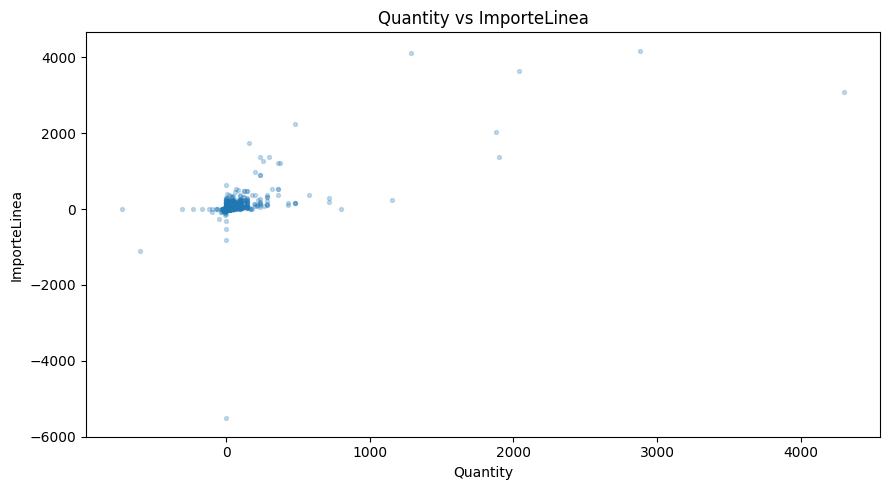


=== NORMALIZACIÓN POR CANTIDAD ===
Cantidad de registros válidos: 541909
Correlación Quantity vs importe por unidad: -0.0012

=== CORRELACIÓN PARCIAL ===
Correlación parcial controlando UnitPrice: 0.8984

=== GRUPO VENTA ===
Registros: 531261
Correlación dentro de VENTA: 0.9001
Correlación parcial dentro de VENTA: 0.9079

=== COMPARACIÓN SIN EXTREMOS ===
Registros en rango central: 526984
Correlación en rango central: 0.6224


In [11]:
def correlacion_parcial(x, y, z):
    """Correlación entre x e y una vez removido el efecto lineal de z."""
    res_x = x - np.polyval(np.polyfit(z, x, 1), z)
    res_y = y - np.polyval(np.polyfit(z, y, 1), z)
    return np.corrcoef(res_x, res_y)[0, 1]

# Actividad 2.3 — El par más correlacionado

# Seleccionar las variables y retirar faltantes
datos = df[
    ['Quantity', 'ImporteLinea', 'UnitPrice',
     'TipoOperacion', 'Country_norm']
].dropna().copy()

x = datos['Quantity']
y = datos['ImporteLinea']
z = datos['UnitPrice']

# 1. Correlación original
print("=== CORRELACIÓN ORIGINAL ===")
print("Quantity vs ImporteLinea:",
      round(x.corr(y), 4))

# Diagrama de dispersión con muestra reproducible
muestra = datos.sample(
    n=min(10000, len(datos)),
    random_state=SEMILLA
)

plt.figure(figsize=(9, 5))
plt.scatter(
    muestra['Quantity'],
    muestra['ImporteLinea'],
    alpha=0.25,
    s=8
)
plt.title('Quantity vs ImporteLinea')
plt.xlabel('Quantity')
plt.ylabel('ImporteLinea')
plt.tight_layout()
plt.show()

# 2. Normalización
# ImporteLinea depende de Quantity por construcción:
# ImporteLinea = Quantity * UnitPrice.
# Se divide por Quantity solo donde esta es distinta de cero.
validos = datos['Quantity'] != 0

importe_por_unidad = (
    datos.loc[validos, 'ImporteLinea']
    / datos.loc[validos, 'Quantity']
)

print("\n=== NORMALIZACIÓN POR CANTIDAD ===")
print("Cantidad de registros válidos:", validos.sum())
print("Correlación Quantity vs importe por unidad:",
      round(
          datos.loc[validos, 'Quantity'].corr(
              importe_por_unidad
          ), 4
      ))

# 3. Correlación parcial controlando UnitPrice
print("\n=== CORRELACIÓN PARCIAL ===")

r_parcial = correlacion_parcial(
    x.to_numpy(dtype=float),
    y.to_numpy(dtype=float),
    z.to_numpy(dtype=float)
)

print("Correlación parcial controlando UnitPrice:",
      round(r_parcial, 4))

# 4. Repetir dentro de un grupo
# Solo operaciones clasificadas como VENTA
ventas = datos.loc[
    datos['TipoOperacion'] == 'VENTA'
]

print("\n=== GRUPO VENTA ===")
print("Registros:", len(ventas))
print("Correlación dentro de VENTA:",
      round(
          ventas['Quantity'].corr(ventas['ImporteLinea']),
          4
      ))

r_ventas = correlacion_parcial(
    ventas['Quantity'].to_numpy(dtype=float),
    ventas['ImporteLinea'].to_numpy(dtype=float),
    ventas['UnitPrice'].to_numpy(dtype=float)
)

print("Correlación parcial dentro de VENTA:",
      round(r_ventas, 4))

# Comprobar el efecto de los extremos
print("\n=== COMPARACIÓN SIN EXTREMOS ===")

centrales = datos.loc[
    datos['Quantity'].between(
        datos['Quantity'].quantile(0.01),
        datos['Quantity'].quantile(0.99)
    )
    &
    datos['ImporteLinea'].between(
        datos['ImporteLinea'].quantile(0.01),
        datos['ImporteLinea'].quantile(0.99)
    )
]

print("Registros en rango central:", len(centrales))
print("Correlación en rango central:",
      round(
          centrales['Quantity'].corr(
              centrales['ImporteLinea']
          ), 4
      ))

_Tu conclusión sobre ese par. ¿Hay relación real, o hay un confundidor? ¿Cuál?_

La correlación entre Quantity e ImporteLinea es alta (0,8867), pero hay que considerar que ImporteLinea se calcula multiplicando Quantity por UnitPrice. Por eso, esta relación está influida por la propia fórmula y no necesariamente representa un comportamiento comercial independiente.

Al dividir ImporteLinea por Quantity, obtenemos prácticamente UnitPrice, cuya correlación con Quantity es -0,0012. Esto muestra que la relación original está vinculada a la forma en que se calcula el importe.

Al controlar UnitPrice mediante correlación parcial, la asociación sigue siendo alta (0,8984). Esto indica que controlar el precio de forma lineal no elimina la relación, ya que el importe depende de la multiplicación entre ambas variables.

Al analizar solamente las operaciones clasificadas como VENTA, la correlación también se mantiene alta (0,9001). Sin embargo, al calcularla únicamente con los registros situados entre los percentiles 1 y 99, disminuye a 0,6224. Esto demuestra que los valores extremos influyen en el resultado, aunque la asociación positiva se mantiene.

En conclusión, existe una asociación positiva entre Quantity e ImporteLinea, pero está condicionada por su relación matemática y por los valores extremos. UnitPrice es un factor importante porque interviene directamente en el cálculo del importe, aunque no corresponde a un confundidor causal clásico. Por lo tanto, no podemos afirmar que esta correlación demuestre una relación causal independiente.

---
## Parte 3 · Series temporales

**Si tu conjunto tiene una variable de fecha, esta parte es obligatoria.** Si no la tiene, reemplázala por un análisis bivariado adicional y dilo explícitamente aquí.

### ✏️ Actividad 3.1 — Construir la serie

Agrega tu conjunto por período (mes, semana o día, según corresponda) y grafica la evolución de tu métrica principal.

=== EVOLUCIÓN MENSUAL DE IMPORTES ===
Meses analizados: 13
Primer mes: 2010-12-01 00:00:00
Último mes: 2011-12-01 00:00:00


,ImporteNeto
InvoiceDate,
2010-12-01,748957.02
2011-01-01,560000.26
2011-02-01,498062.65
2011-03-01,683267.08
2011-04-01,493207.12
2011-05-01,723333.51
2011-06-01,691123.12
2011-07-01,681300.11
2011-08-01,682680.51


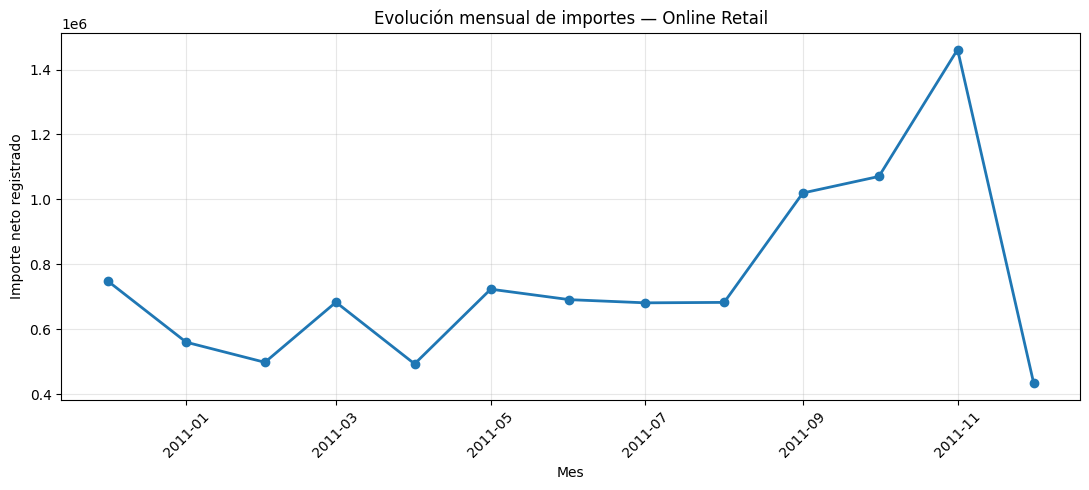


Mes con mayor importe: 2011-11 1461756.25
Mes con menor importe: 2011-12 433668.01


In [12]:
# Actividad 3.1 — Construir la serie temporal

# Trabajar con una copia sin modificar el dataset original
df_temporal = df.copy()

# Asegurar que InvoiceDate sea una fecha
df_temporal['InvoiceDate'] = pd.to_datetime(
    df_temporal['InvoiceDate'],
    errors='coerce'
)

# Agrupar los importes por mes
serie_mensual = (
    df_temporal
    .dropna(subset=['InvoiceDate'])
    .set_index('InvoiceDate')['ImporteLinea']
    .resample('MS')
    .sum()
)

print("=== EVOLUCIÓN MENSUAL DE IMPORTES ===")
print("Meses analizados:", len(serie_mensual))
print("Primer mes:", serie_mensual.index.min())
print("Último mes:", serie_mensual.index.max())

display(
    serie_mensual.rename('ImporteNeto').to_frame().round(2)
)

# Gráfico de evolución mensual
plt.figure(figsize=(11, 5))

plt.plot(
    serie_mensual.index,
    serie_mensual.values,
    marker='o',
    linewidth=2
)

plt.title('Evolución mensual de importes — Online Retail')
plt.xlabel('Mes')
plt.ylabel('Importe neto registrado')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Resumen de meses con mayores y menores importes
print("\nMes con mayor importe:",
      serie_mensual.idxmax().strftime('%Y-%m'),
      round(serie_mensual.max(), 2))

print("Mes con menor importe:",
      serie_mensual.idxmin().strftime('%Y-%m'),
      round(serie_mensual.min(), 2))



**Interpretación de la evolución mensual**

Al revisar la evolución de los importes, observo que entre enero y agosto de 2011 existen varias fluctuaciones, sin una tendencia claramente definida. Sin embargo, desde septiembre los importes aumentan y alcanzan su valor más alto en noviembre de 2011, con 1.461.756,25.

Este aumento podría estar relacionado con una mayor actividad comercial hacia fin de año, aunque no se puede asegurar que sea un comportamiento estacional porque contamos con poco más de un año de datos.

También se observa una caída importante en diciembre de 2011, pero este mes solo contiene registros hasta el día 9. Por eso no sería correcto compararlo directamente con los meses completos.

En conclusión, los datos muestran un crecimiento de los importes hacia los últimos meses de 2011, aunque debemos considerar que incluyen cancelaciones y ajustes y que el último mes está incompleto.

### ✏️ Actividad 3.2 — Descomposición

Si tu serie tiene al menos **dos ciclos completos** (por ejemplo, 24 meses), descompónla en tendencia, estacionalidad y residuo.

Después responde: ¿qué muestra el **residuo**? ¿Hay algún período anómalo?

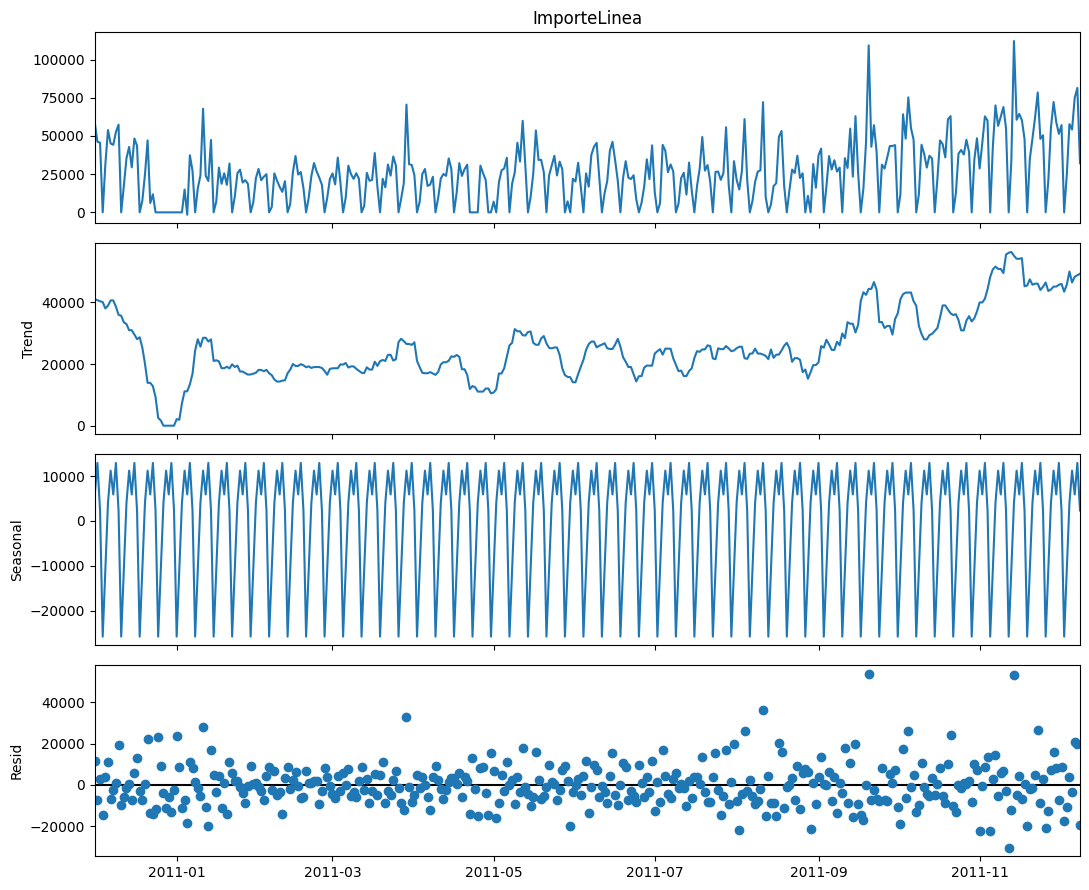

=== RESUMEN DE RESIDUOS ===
Días analizados: 374
Media del residuo: 21.75
Desviación estándar: 10558.32

=== DÍAS CON MAYORES RESIDUOS ABSOLUTOS ===


,Residuo,ImporteDia
InvoiceDate,,
2011-09-20,53701.99,109286.21
2011-11-14,52975.65,112141.11
2011-08-11,36143.28,72132.79
2011-03-29,32809.33,70531.47
2011-11-12,-30304.81,0.00
2011-01-11,28097.05,67817.13
2011-11-23,26499.36,78480.70
2011-08-04,26216.40,61028.65
2011-10-05,26169.89,75244.43


In [13]:
# from statsmodels.tsa.seasonal import seasonal_decompose
# desc = seasonal_decompose(serie, model='additive', period=12)
# fig = desc.plot(); fig.set_size_inches(9, 8); plt.tight_layout(); plt.show()

# Actividad 3.2 — Descomposición de serie temporal

from statsmodels.tsa.seasonal import seasonal_decompose

# Construir una serie diaria de importes
serie_diaria = (
    df.dropna(subset=['InvoiceDate'])
    .set_index('InvoiceDate')['ImporteLinea']
    .resample('D')
    .sum()
    .asfreq('D', fill_value=0)
)

# Descomposición con periodicidad semanal (7 días)
descomposicion = seasonal_decompose(
    serie_diaria,
    model='additive',
    period=7,
    extrapolate_trend='period'
)

fig = descomposicion.plot()
fig.set_size_inches(11, 9)
plt.tight_layout()
plt.show()

# Revisar residuos
residuos = descomposicion.resid.dropna()

print("=== RESUMEN DE RESIDUOS ===")
print("Días analizados:", len(serie_diaria))
print("Media del residuo:", round(residuos.mean(), 2))
print("Desviación estándar:", round(residuos.std(), 2))

# Identificar días con residuos de mayor magnitud
residuos_extremos = residuos.abs().nlargest(10)

print("\n=== DÍAS CON MAYORES RESIDUOS ABSOLUTOS ===")

display(
    pd.DataFrame({
        'Residuo': residuos.loc[residuos_extremos.index],
        'ImporteDia': serie_diaria.loc[residuos_extremos.index]
    }).round(2)
)

**Tu lectura de la tendencia, la estacionalidad y el residuo:**

Tendencia: Los importes diarios presentan variaciones durante gran parte de 2011, pero desde septiembre se observa un crecimiento más marcado, especialmente hacia noviembre. Esto coincide con el aumento que encontramos en el análisis mensual.

Estacionalidad: Se identifica un patrón semanal que se repite aproximadamente cada siete días. Esto podría relacionarse con diferencias en la actividad comercial según el día de la semana. Sin embargo, hay que considerar que los días sin registros fueron representados con valor cero.

Residuo: La mayoría de los residuos se mantiene cerca de cero, aunque existen días con diferencias importantes. Por ejemplo, el 20 de septiembre de 2011 presenta un residuo positivo de 53.701,99 y el 14 de noviembre uno de 52.975,65. En cambio, el 12 de noviembre presenta un residuo negativo de -30.304,81, con un importe diario de cero.

Conclusión: El análisis muestra un crecimiento hacia los últimos meses de 2011 y un patrón semanal en los registros. También aparecen días anómalos que podrían corresponder a operaciones extraordinarias o diferencias en la actividad comercial, pero no podemos afirmar que sean errores sin investigar sus causas. Además, el período disponible no permite confirmar una estacionalidad anual.

### ✏️ Actividad 3.3 — La comparación honesta

Si tu serie tiene estacionalidad, calcula la variación entre dos períodos consecutivos y la variación interanual del mismo período. Muestra la diferencia entre ambas lecturas (Ejercicio 6).

=== VARIACIONES MENSUALES E INTERANUALES ===


,ImporteNeto,Variacion_Mensual_%,Variacion_Interanual_%
InvoiceDate,,,
2010-12-01,748957.02,NaN,NaN
2011-01-01,560000.26,-25.23,NaN
2011-02-01,498062.65,-11.06,NaN
2011-03-01,683267.08,37.18,NaN
2011-04-01,493207.12,-27.82,NaN
2011-05-01,723333.51,46.66,NaN
2011-06-01,691123.12,-4.45,NaN
2011-07-01,681300.11,-1.42,NaN
2011-08-01,682680.51,0.20,NaN



=== OCTUBRE VS NOVIEMBRE 2011 ===
Importe octubre: 1070704.67
Importe noviembre: 1461756.25
Variación mensual: 36.52 %

=== LIMITACIÓN INTERANUAL ===
No existe una comparación interanual mensual
válida entre dos meses completos del conjunto.
Diciembre 2011 solo contiene datos hasta el día 9.


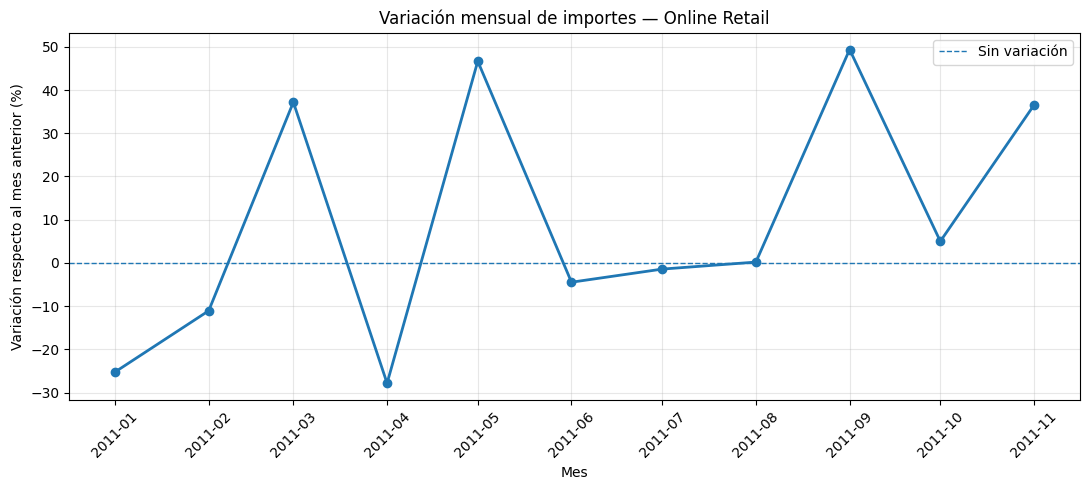


=== VERIFICACIÓN DEL GRÁFICO ===
Último mes representado: 2011-11
Diciembre 2011 excluido solo del gráfico.
El dataset original no fue modificado.


In [14]:
# Actividad 3.3 — La comparación honesta

# Utilizar la serie mensual creada en la Actividad 3.1
comparacion = serie_mensual.to_frame(name='ImporteNeto')

# 1. Variación respecto al mes anterior
comparacion['Variacion_Mensual_%'] = (
    comparacion['ImporteNeto']
    .pct_change(fill_method=None) * 100
)

# 2. Variación respecto al mismo mes del año anterior
comparacion['Variacion_Interanual_%'] = (
    comparacion['ImporteNeto']
    .pct_change(periods=12, fill_method=None) * 100
)

# Diciembre de 2011 está incompleto (solo hasta el día 9).
# Su comparación interanual no es equivalente.
comparacion.loc[
    '2011-12-01',
    'Variacion_Interanual_%'
] = np.nan

# 3. Mostrar tabla completa
print("=== VARIACIONES MENSUALES E INTERANUALES ===")
display(comparacion.round(2))

# 4. Comparar octubre y noviembre de 2011
octubre = comparacion.loc['2011-10-01', 'ImporteNeto']
noviembre = comparacion.loc['2011-11-01', 'ImporteNeto']

variacion = (noviembre / octubre - 1) * 100

print("\n=== OCTUBRE VS NOVIEMBRE 2011 ===")
print("Importe octubre:", round(octubre, 2))
print("Importe noviembre:", round(noviembre, 2))
print("Variación mensual:", round(variacion, 2), "%")

# 5. Documentar la limitación interanual
print("\n=== LIMITACIÓN INTERANUAL ===")
print("No existe una comparación interanual mensual")
print("válida entre dos meses completos del conjunto.")
print("Diciembre 2011 solo contiene datos hasta el día 9.")

# 6. Preparar gráfico usando solamente meses completos
# Excluimos diciembre 2011 únicamente del gráfico.
comparacion_grafico = comparacion.loc[:'2011-11-01'].copy()

plt.figure(figsize=(11, 5))

plt.plot(
    comparacion_grafico.index,
    comparacion_grafico['Variacion_Mensual_%'],
    marker='o',
    linewidth=2
)

plt.axhline(
    0,
    linestyle='--',
    linewidth=1,
    label='Sin variación'
)

plt.title(
    'Variación mensual de importes — Online Retail'
)
plt.xlabel('Mes')
plt.ylabel('Variación respecto al mes anterior (%)')

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 7. Confirmar período utilizado en el gráfico
print("\n=== VERIFICACIÓN DEL GRÁFICO ===")
print("Último mes representado:",
      comparacion_grafico.index.max().strftime('%Y-%m'))
print("Diciembre 2011 excluido solo del gráfico.")
print("El dataset original no fue modificado.")


**Interpretación de la comparación temporal**

Al comparar los importes entre meses consecutivos, se observan aumentos y disminuciones importantes. Por ejemplo, entre octubre y noviembre de 2011 el importe registrado aumentó un 36,52 %, pasando de 1.070.704,67 a 1.461.756,25.

También aparecen aumentos importantes entre abril y mayo (46,66 %) y entre agosto y septiembre (49,37 %). Estas variaciones muestran cambios en la actividad registrada, pero no permiten asegurar que exista un crecimiento permanente.

En diciembre de 2011, la tabla muestra una disminución de 70,33 % respecto de noviembre. Sin embargo, este resultado no representa necesariamente una caída real, porque el conjunto solo contiene información hasta el día 9. Por esta razón, diciembre se excluyó del gráfico de variaciones mensuales, pero se mantuvo en la tabla y en el conjunto original.

No fue posible realizar una comparación interanual mensual válida porque no contamos con dos años completos de información. El único mes presente en ambos años es diciembre, pero sus períodos no son equivalentes.

En conclusión, las comparaciones mensuales permiten observar cambios importantes, pero debemos considerar la estacionalidad y la cobertura de los datos antes de sacar conclusiones sobre el crecimiento de las ventas.

---
## Parte 4 · Hipótesis de trabajo

Esto es lo que la semana 4 va a poner a prueba. Una hipótesis de trabajo no es una corazonada: es una afirmación **falsable** que surge de la evidencia que acabas de producir.

### ✏️ Actividad 4.1 — Formula dos hipótesis

Cada una debe indicar:

- **La afirmación**, en una frase.
- **La evidencia exploratoria** que la sugiere (qué gráfico, qué número, en qué celda).
- **Qué la refutaría**: qué tendrías que observar para descartarla.
- **Qué confundidor podría explicarla** sin que la relación sea real.

Si no puedes escribir qué la refutaría, no es una hipótesis: es una opinión.

**Hipótesis 1 — Diferencias de importes entre países**

Afirmación: Las líneas de factura de Países Bajos presentan un importe mediano mayor que las de Reino Unido, incluso al comparar operaciones con cantidades similares.

Evidencia: En la Actividad 2.1, la mediana de ImporteLinea de Países Bajos fue 91,80, mientras que la de Reino Unido fue 8,29. Los grupos tienen 2.371 y 495.478 registros, respectivamente.

Qué la refutaría: Que al comparar operaciones con cantidades similares la diferencia de medianas desaparezca o se invierta.

Confundidor posible: La cantidad de productos por línea de factura (Quantity), ya que compras de mayor volumen pueden generar importes más altos sin que necesariamente existan diferencias en los precios unitarios.


**Hipótesis 2 — Crecimiento de importes hacia fin de año**

Afirmación: El importe neto mensual registrado durante septiembre, octubre y noviembre de 2011 fue mayor, en promedio, que durante los meses de enero a agosto del mismo año.

Evidencia: En las Actividades 3.1 y 3.3 se observó un aumento de los importes desde septiembre de 2011. Entre agosto y septiembre el crecimiento fue de 49,37 %, y entre octubre y noviembre fue de 36,52 %.

Qué la refutaría: Que al calcular y comparar los promedios mensuales de ambos períodos, el promedio de septiembre a noviembre no sea superior al de enero a agosto.

Confundidor posible: Los cambios en la cantidad de operaciones registradas por mes, ya que un mayor importe total podría deberse a más transacciones y no necesariamente a mayores importes por operación.

---
## Parte 5 · Cierre y versionado

In [15]:
# Parte 5 — Guardar el conjunto explorado

ARCHIVO_SALIDA = 'S3_Online_Retail_Explorado.csv'

df.to_csv(
    ARCHIVO_SALIDA,
    sep=';',
    index=False,
    encoding='utf-8-sig',
    date_format='%Y-%m-%d %H:%M:%S'
)

print("Archivo guardado:", ARCHIVO_SALIDA)
print("Dimensiones:", df.shape)

Archivo guardado: S3_Online_Retail_Explorado.csv
Dimensiones: (541909, 18)


In [16]:
# En una terminal:
# git add S3_Notebook_Laboratorio_CDD.ipynb mi_conjunto_explorado.csv
# git commit -m 'Semana 3: analisis exploratorio y series temporales'
# git push


**Enlace a mi repositorio:** https://github.com/fariasad/UCSC-Ciencia-de-Datos


## Antes de entregar

- [x] Al menos tres distribuciones graficadas y **leídas**, no solo mostradas
- [x] Media contra mediana decidida y justificada
- [x] Comparación por grupos con el `count` incluido
- [x] Matriz de correlación calculada e interpretada
- [x] El par más correlacionado sometido al recorrido de confundidores
- [x] Serie temporal descompuesta, con lectura del residuo (o justificación de por qué no aplica)
- [x] Dos hipótesis de trabajo, cada una con qué la refutaría
- [x] Cada celda de código seguida de su celda de interpretación
- [x] Cuaderno ejecutado de principio a fin, con las salidas visibles

Recuerda: **esta semana no hay sesión sincrónica**. Las dudas, al Foro de Consultas.

_Ciencia de Datos · Advance UCSC · Semana 3_